# HDS-M03: Biomedical Image Analysis (Deep Learning)

### Required packages

[1] [matplotlib](http://matplotlib.org) can be used for plotting graphs in python

[2] [pytorch](https://pytorch.org/docs/stable/index.html) is library widely used for bulding deep-learning frameworks

[3] [Tensorboard](https://pytorch.org/docs/stable/tensorboard.html) is used to visualise your training and validation loss and accuracy development - It is important to observe it!!!

[4] [TorchVision](https://pytorch.org/vision/stable/index.html) you can use available datasets that include one you are required to use in this course (e.g. CIFAR10) and also use augmentations (meaning you can increase data variability for improved accuracy and model generalisation)

[5] [Scikit-learn](https://scikit-learn.org/stable/) Metrics to evaluate quality of segmentation 

**Reference:** 

[1] Original U-Net paper: https://arxiv.org/pdf/1505.04597.pdf

[2] Link to presentation: https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/


**What will you learn here?**

- You wil learn how to load your custom data for semantic segmentation task

- You will make an encoder-decoder U-Net architecture 

- You will learn how to group repeated blocks into one while designing U-Net

<img src="https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/u-net-architecture.png" style="width:800px;height:400px;">
<caption><center> <u>Figure</u>: U-Net architecture for image segmentation.</center></caption>

**Concentrate on:**

[1] Encoder layers (this is similar to your classification exercise)

[2] Decoder layers (upscaling of images occur here as you want to obtain per-pixel segmentation)

In [1]:
import torch
import torchvision 
from torch import nn
import torch.nn.functional as F
from torch import optim
import numpy as np

# always check your version
print("PyTorch version: ",torch.__version__)
print ("GPU available?", torch.cuda.is_available())

PyTorch version:  2.14.1+cu126
GPU available? True


#### New : We will setup a seed for reproducibility 
- Setting a seed helps to regenerate the same result

In [2]:
import random
random_seed= 42 # why 42?
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
torch.cuda.manual_seed(random_seed)
torch.backends.cudnn.deterministic = True

### Data loading and pre-processing
**Steps**

[1] Load data - data is provided already available for you to use in ``/data/cdtshared/Cohort-2024/HDS-M03/MontgomerySet/``
- Images are in folder ``/data/cdtshared/Cohort-2024/HDS-M03/MontgomerySet/CXR_png``
- Corresponding masks:
    - Left Mask in ``/data/cdtshared/Cohort-2024/HDS-M03/MontgomerySet/ManualMask/leftMask``
    - Right Mask in ``/data/cdtshared/Cohort-2024/HDS-M03/MontgomerySet/ManualMask/rightMask``
- Data format and size: All are in ``.png`` and of variable size (you may want to resize them to 256x256 for your practicals)

[2] Transform --> Normalise your data - mean and std (e.g., if color then normalise all three channels)
e.g., torchvision.transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))

[3] Transform --> Always convert data to ToTensor (you can do **step 1, 2 and 3** in one line as done in this tutorial)

[4] Split your data into **train, validation, and test set**

[4] Make [DataLoaders](https://pytorch.org/docs/stable/data.html): It represents a Python iterable over a dataset

[5] Identify labels 


In [3]:
from torchvision import transforms 
from torch.utils.data import DataLoader

In [4]:
from PIL import Image # For reading your custom data images
import os
import glob

# Load data and include prepared transform (Remember to apply same transform to both image and label) 
class mySegmentationData(object):
    def __init__(self, root, transforms = None):
        self.root = root
        self._eval = eval
        self.transforms = transforms
        self.build_dataset()
        
    def build_dataset(self):   
        self.imgs = os.path.join(self.root, "CXR_png")
        self.masks_L = os.path.join(self.root, "ManualMask/leftMask")
        self.masks_R = os.path.join(self.root, "ManualMask/rightMask")
        
        # Exclude the outlier image and its paired masks before splitting.
        self._images = [path for path in sorted(glob.glob(self.imgs + "/*.png"))
                        if os.path.basename(path) != "MCUCXR_0354_1.png"]
        
        # Pair both lung labels with each image by filename.
        self._labels = [(os.path.join(self.masks_L, os.path.basename(path)),
                         os.path.join(self.masks_R, os.path.basename(path)))
                        for path in self._images]
        
        
    def __getitem__(self, idx):
        img = Image.open(self._images[idx]).convert("L").resize((256,256), resample=0)
        left_path, right_path = self._labels[idx]
        left = Image.open(left_path).convert("L").resize((256, 256), resample=0)
        right = Image.open(right_path).convert("L").resize((256, 256), resample=0)
        mask = Image.fromarray(np.maximum(np.asarray(left), np.asarray(right)))
        if self.transforms is not None:
            img = self.transforms(img)
            mask = self.transforms(mask)
   
        return img, mask
    
    def __len__(self):
        return len(self._images)

#### New: You will split train data into train, val, and test set (e.g. 80%-10%-10%) 
- This step is crucial to identify under- and over-fitting problems 
- Later, we will visualise performance on both train, val, and test online during training (using tensorboard)

In [5]:
# Step: Split between train, val, and test from the overall trainset
transform = transforms.Compose([transforms.ToTensor(), transforms.Resize((256,256))])
# transforms.Resize((256,256))
mydataset = mySegmentationData(root='/data/cdtshared/Cohort-2024/HDS-M03/MontgomerySet/', transforms=transform)

#  same as you did in classification (here we are doing )
from torch.utils.data.sampler import SubsetRandomSampler

val_percentage = 0.2
test_percentage = 0.2
num_train = len(mydataset)

indices = list(range(num_train))
val_split = int(np.floor(val_percentage * num_train))
test_split = int(np.floor(test_percentage * num_train))

train_idx, valid_idx, test_idx = indices[(val_split+test_split):], indices[:val_split], indices[val_split:(val_split+test_split)]

train_sampler = SubsetRandomSampler(train_idx)
valid_sampler = SubsetRandomSampler(valid_idx)
test_sampler = SubsetRandomSampler(test_idx)

print('Data set split (train/val/test): {:d}/{:d}/{:d}'.format(len(train_sampler),len(valid_sampler), len(test_sampler)))

# Now create data loaders (same as before)
# Now we need to create dataLoaders that will allow to iterate during training
batch_size = 16 # create batch-based on how much memory you have and your data size

traindataloader = DataLoader(mydataset, batch_size=batch_size, sampler=train_sampler, num_workers=0)
valdataloader = DataLoader(mydataset, batch_size=batch_size, sampler=valid_sampler,
            num_workers=0,)
testdataloader = DataLoader(mydataset, batch_size=batch_size, sampler=test_sampler,
            num_workers=0,)

Data set split (train/val/test): 84/27/27


In [6]:
print('Number of training batches:', len(traindataloader))
print('Number of validation batches:', len(valdataloader))
print('Number of test batches:', len(testdataloader))
# print('Number of testing samples:', len(testdataloader))

Number of training batches: 6
Number of validation batches: 2
Number of test batches: 2


### Look into data

In [7]:
# function to unnormalise images and using transpose to change order to [H, W, Channel] 
def imshow(img):
    # TODO: unnormalize if needed
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

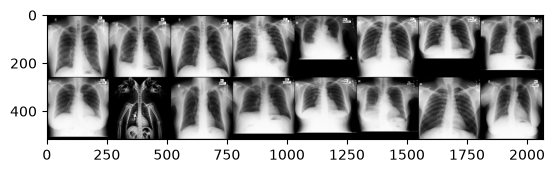

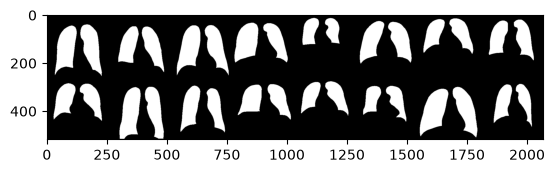

In [8]:
import matplotlib.pyplot as plt 
%matplotlib inline

# always check the shape of your training data
dataiter = iter(traindataloader)
images, masks = next(dataiter)

# show images 
imshow(torchvision.utils.make_grid(images))
imshow(torchvision.utils.make_grid(masks))
# print labels
# print(' '.join('%5s' % classes[labels[j]] for j in range(batch_size)))


### Create your UNet model
- Please note that your input image size will make difference on your hard-coded feature sizes in FC-layer
- Always be aware of what size input is used, here for convenience we will follow the original paper and reshape image to 224x224x3 

<img src="https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/u-net-architecture.png" style="width:800px;height:400px;">
<caption><center> <u>Figure</u>: U-Net architecture for image segmentation.</center></caption>

**Hint**
- You will implement an encoder-decoder U-Net architecture 
    - Implement a baseblock with --> two convolution with kernel_size 3 and padding 1 with ReLU 
    - Implement output block with 1 convolution
    - For encoder you will use maxpooling with kernel 2
    - For decoder you will use upsampling using ConvTranspose2d
    - Both encoder and decoder will have **baseblock**
    

- You will learn how to group repeated blocks into one while designing U-Net

In [9]:
# Step 1: Build a nn.Sequential with two conv-BatchN-Relu layers
def baseblock(channel_in, channel_out):
#     Design a baseblock with Conv2d-BatchNorm2d-ReLU x 2 (each input is twice convolved as in fig.)
    return nn.Sequential(
            torch.nn.Conv2d(channel_in, channel_out, 3, padding=1),
            torch.nn.BatchNorm2d(channel_out),
            torch.nn.LeakyReLU()
        )  

# Step 2: Build a downscaling module [Hint: use the baseblock implemented above]
# Add a maxpool before baseblock as in figure
def downsamplePart(channel_in, channel_out):
    return nn.Sequential(
            torch.nn.MaxPool2d(2),
            baseblock(channel_in, channel_in),
            baseblock(channel_in, channel_out)
        )

# Step 3: Build a upscaling module [Hint: use the baseblock implemented above]
# Add ConvTranspose2d before baseblock as in figure
# Remember there is also concatenation and size may change so we are padding
class upsampledPart(nn.Module):
    def __init__(self, channel_in, channel_out, bilinear=True):
        super().__init__()
        # to implement

        self.up = torch.nn.ConvTranspose2d(channel_in, channel_out, 2, stride=2)
        self.double_conv = torch.nn.Sequential(
            baseblock(channel_in, channel_out),
            baseblock(channel_out, channel_out)
        )

        
    def forward(self, x1, x2):
        # x1 is the more compressed element
        # upscale and then pad to eliminate any difference between upscaled and other feature map coming with skip connection     
        x1 = self.up(x1)
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]
        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2, diffY // 2, diffY - diffY // 2] )
        
        # concatenate (perform concatenation of x1 and x2 --> remember these are skip x2(from encoder) and upssampled image x1)
        x = torch.cat([x2, x1], dim=1)
        
        # apply baseblock after concatenation --> you do again two convs.? --> baseblock
        x = self.double_conv(x)

        return x
    
# Step 4: Compile all of above together
# here output channel should be equal to number of classes
class UNet(nn.Module):
    def __init__(self, channel_in, channel_out, bilinear=None, dropout_level=0.5):
        super(UNet,self).__init__()
        self.channel_in = channel_in
        self.channel_out = channel_out
        self.dropout = torch.nn.Dropout2d(dropout_level)
        
        #call your base block
        self.initial = baseblock(channel_in, 64)
        
        # downsampling layers with 2 conv layers (You NEED to put some numbers inside ##)
        self.down1 = downsamplePart( 64, 128)
        self.down2 = downsamplePart(128, 256)
        self.down3 = downsamplePart(256, 512)
        self.down4 = downsamplePart(512, 1024)
        
        # upsampling layers with feature concatenation and 2 conv layers (You NEED to put some numbers inside ##)
        self.up1 = upsampledPart(1024, 512) 
        self.up2 = upsampledPart(512, 256)
        self.up3 = upsampledPart(256, 128)
        self.up4 = upsampledPart(128, 64)
        
        # output layer
        self.out = nn.Conv2d(64, channel_out, kernel_size=1) 

    # build a forward pass here
    # remember to keep your output as you will need to concatenate later in upscaling
    def forward(self,x):
        x1 = self.initial(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x4 = self.dropout(x4)
        x5 = self.down4(x4)
        x5 = self.dropout(x5)

        # your code here for upscaling
        x = self.up1(x5, x4)
        x = self.dropout(x)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        # output
        return self.out(x)  

### Training your model

### Prepare an optimizer, set learning rate, and you loss function
- Here you will use model.train and use gradients
- Also, you will use criterion to compute loss 
- Compute metric to know how well it is performing
- save them to display mean for each epoch

In [10]:
# call you model 
model = UNet(channel_in=1, channel_out= 1)
lr = 0.001

# Optimiser
optimiser = torch.optim.Adam(model.parameters(), lr = lr, weight_decay = 1e-8)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

criterion = nn.BCEWithLogitsLoss()
model = model.to(device)
criterion = criterion.to(device)

### Prepare accuracy computation to know how your training is going 

[1] Loss function is important to keep track (mostly you minimise it, i.e. it should go down)

[2] Dice coefficient is also important (in segmentation) and you want higher score

[3] You can use TensorBoard to visualize loss function and other metrics

In [11]:
# Create metrics
def dice(a, b):
    """Calculate dice score for each image in tensor"""
    # a and b are tensors of shape (B, C, H, W)
    # Sum over last two axes (H and W i.e. each image)
    return 2*(a*b).sum(axis=[-2, -1])/(a + b).sum(axis=[-2,-1]).type(torch.float32)

def mask_out(out):
    """Mask tensor/array with 0 threshold"""
    # Need to binarize the output to be able to calculate Dice score
    return out > 0

def get_dice_arr(out, label):
    """Get dice score for each image in the batch for each mask seperately"""
    # Output is shape (B, C)
    return dice(mask_out(out), label)

In [ ]:
# Training & validation: 
model.to(device)
model.train()

from pathlib import Path
from torch.utils.tensorboard import SummaryWriter

# "auto": latest checkpoint if available, otherwise best weights.
# Use "best" or "last" to select explicitly, or None for a fresh run.
resume_from = "auto"
ckptFileName = 'UNet_CKPT_best.pt'
last_ckpt_filename = 'UNet_CKPT_last.pt'
# Last completed epoch reported for the original weights-only best checkpoint.
legacy_best_epoch = 90
start_epoch = 0
best_valid_loss = float('inf')

if resume_from not in ("auto", "best", "last", None):
    raise ValueError('resume_from must be "auto", "best", "last", or None')
resume_path = None
if resume_from == "auto":
    if Path(last_ckpt_filename).is_file():
        resume_path = Path(last_ckpt_filename)
    elif Path(ckptFileName).is_file():
        resume_path = Path(ckptFileName)
elif resume_from is not None:
    resume_path = Path(last_ckpt_filename if resume_from == "last" else ckptFileName)

if resume_path is not None:
    checkpoint = torch.load(resume_path, map_location=device, weights_only=True)
    if 'model_state_dict' in checkpoint:
        model.load_state_dict(checkpoint['model_state_dict'])
        optimiser.load_state_dict(checkpoint['optimizer_state_dict'])
        start_epoch = checkpoint['epoch'] + 1
        best_valid_loss = checkpoint['best_valid_loss']
        print(f'Resuming {resume_path} at epoch {start_epoch} with optimizer state.')
    else:
        # The original best checkpoint contains model weights only.
        model.load_state_dict(checkpoint)
        start_epoch = legacy_best_epoch + 1
        # Start a new Adam history when loading weights only.
        optimiser.state.clear()
        model.eval()
        baseline_losses = []
        with torch.no_grad():
            for data, label in valdataloader:
                out = model(data.to(device))
                baseline_losses.append(criterion(out, label.to(device)).item())
        best_valid_loss = float(np.mean(baseline_losses))
        print(f'Loaded best weights from {resume_path}; validation loss {best_valid_loss:.6f}.')
        print(f'Weights-only checkpoint: assuming epoch {legacy_best_epoch} completed; continuing at epoch {start_epoch} with fresh optimizer history.')
    del checkpoint
else:
    print('Starting training from current model weights without a checkpoint.')

# Total epoch target (zero-based epoch labels run through 499).
epochs = 500
log_interval = 4
writer = SummaryWriter()

for epoch in range(start_epoch, epochs):
    train_loss, valid_loss, train_dsc,val_dsc  = [], [], [], []
    
    model.train()
    for batch_idx, (data, label) in enumerate(traindataloader):
        
        # initialise all your gradients to zero
        label = label.to(device)
        optimiser.zero_grad()
        out = model(data.to(device))

        loss = criterion(out, label)
        loss.backward()
        optimiser.step()
        
        # append
        train_loss.append(loss.item())
        acc_1 = get_dice_arr(out, label.to(device))
        train_dsc.append(acc_1.mean(axis=0).detach().cpu().numpy())
        
        if (batch_idx % log_interval) == 0:
            print('Train Epoch is: {}, train loss is: {:.6f} and train Dice: {:.6f}'.format(epoch, np.mean(train_loss),np.mean(train_dsc)))
    
    model.eval()
    with torch.no_grad():
        for i, (data, label) in enumerate(valdataloader):
            data, label = data.to(device), label.to(device)
            out = model(data)
            loss = criterion(out, label.to(device))
            acc_1 = get_dice_arr(out, label.to(device))

            # append
            val_dsc.append(acc_1.mean(axis=0).detach().cpu().numpy())
            valid_loss.append(loss.item())

    print('Val Epoch is: {}, val loss is: {:.6f} and val Dice: {:.6f}'.format(epoch, np.mean(valid_loss), np.mean(val_dsc)))
    
    # Keep the best checkpoint as weights for compatibility with the test cell.
    if np.mean(valid_loss) < best_valid_loss:
        best_valid_loss = float(np.mean(valid_loss))
        print('saving my model, improvement in validation loss achieved...')
        best_tmp = ckptFileName + '.tmp'
        torch.save(model.state_dict(), best_tmp)
        os.replace(best_tmp, ckptFileName)

    # Replace the latest checkpoint only after the new file is fully written.
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimiser.state_dict(),
        'best_valid_loss': best_valid_loss,
    }
    last_tmp = last_ckpt_filename + '.tmp'
    torch.save(checkpoint, last_tmp)
    os.replace(last_tmp, last_ckpt_filename)
    del checkpoint

    # every epoch write the loss and accuracy (these you can see plots on tensorboard)        
    writer.add_scalar('UNet/train_loss', np.mean(train_loss), epoch)
    writer.add_scalar('UNet/train_accuracy', np.mean(train_dsc), epoch)
    
    # New --> add plot for your val loss and val accuracy
    writer.add_scalar('UNet/val_loss', np.mean(valid_loss), epoch)
    writer.add_scalar('UNet/val_accuracy', np.mean(val_dsc), epoch)
    
writer.close()

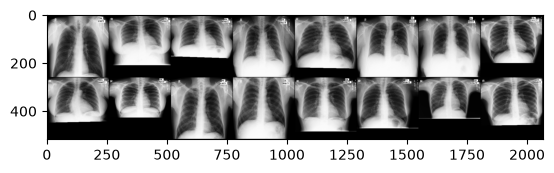

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-9.114192..11.396846].


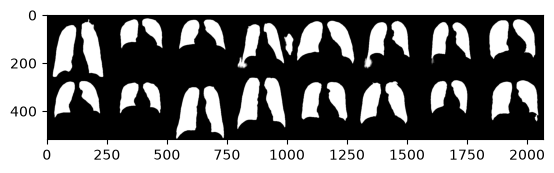

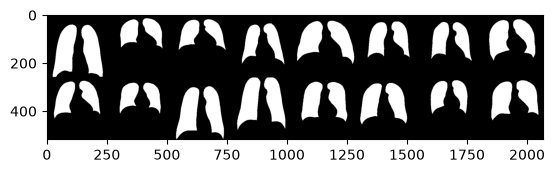

In [13]:
total = 0
model.eval()
dataiter = iter(valdataloader)
images, masks = next(dataiter)
output = model(images.to(device))

# show images 
imshow(torchvision.utils.make_grid(images))
imshow(torchvision.utils.make_grid(output.detach().cpu()))
imshow(torchvision.utils.make_grid(masks))

In [25]:
def calc_model_loader_dice(model, dataloader):
    total_loss = 0.0
    total_dice = 0.0
    count = 0
    model.eval()

    with torch.no_grad():
        for data, label in dataloader:
            data, label = data.to(device), label.to(device)
            out = model(data)
            batch_size = data.size(0)

            total_loss += criterion(out, label).item() * batch_size
            total_dice += get_dice_arr(out, label).mean(dim=1).sum().item()
            count += batch_size

    return total_loss / count, total_dice / count

In [26]:
### TODO: compute the accuracy of your model on validation set --> You are required to use Dice similarity coefficient
val_loss_final, val_dsc_final = calc_model_loader_dice(model, valdataloader)
print('loss is: {:.6f} and val Dice: {:.6f}'.format(np.mean(val_loss_final), np.mean(val_dsc_final)))


loss is: 0.035414 and val Dice: 0.972968


In [ ]:
# TODO: Apply on your test data set and report your result
ckptFileName = 'UNet_CKPT_best.pt'
# load the saved weights
model.load_state_dict(torch.load(ckptFileName))

# Apply testing (same as validation above)
# Your code here... (same as validation code)
test_loss_final, test_dsc_final = calc_model_loader_dice(model, testdataloader)
print('loss is: {:.6f} and val Dice: {:.6f}'.format(np.mean(test_loss_final), np.mean(test_dsc_final)))




### Improving your network performance
p.s. this is open-ended exercise. You can pick only some questions to investigate!

- Report results on testing data set! (some code to write)
- Train for larger batch size and more epochs
- Add data augmentation provided in transforms (https://pytorch.org/vision/stable/transforms.html) -- Ask tutor if you  are confused 
- Train your network by combining both left and right lung segmentation (report accuracy and loss curves)
- Look into your train/val/test data sets and check whether they are representative of population (TB vs normal)
- You can use change loss function (e.g. for Dice loss), or combine different loss funtions as well
- Consider ensemble models (how to generate different models?, optimers, loss functions, initialisations, etc)
- Consider segmentation of left and right lung separately (instance segmentation)
- Compare your model with Pytorch segmentation model (deeplab_v3, see here: https://pytorch.org/hub/pytorch_vision_deeplabv3_resnet101/)


#### Exercise: Perform above improvements on  chest X-ray imaging
- You can use this ipython notebook to do this (**Assignment to be submmitted**)
- Due on **Friday 1st November, 2024 (6.00PM)** (*This exercise is used for assessment of Module: Biomedical Image Analysis *)

<h3>Thanks for completing this lesson!</h3>
The tutorial was written by Dr A. Sharib. (revised by Bartek Papiez, Oct 2022, Oct 2024). <br>
Any comments or feedbacks and your solution to exercise, please send to bartomiej.papiez@bdi.ox.ac.uk 